# 12 — Selected-stock walk-forward predictions, 2015–2025

This notebook visualizes actual closing-auction volume and leakage-safe rolling predictions for six continuously covered stocks representing different size and liquidity regimes.

The panel begins in 2015, so 2015 is a **warm-up year with actuals only**. A valid frozen-model forecast cannot be constructed for that year because no earlier auction history exists in the supplied dataset. Predictions begin in 2016. Each prediction year uses an annually refitted global model trained only on earlier dates; daily lagged covariates continue to update through the prediction year.

For readability, the charts emphasize 20-trading-day rolling medians while retaining faint daily series. The saved prediction file contains every daily observation.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")
sys.path.insert(0, str(PROJECT_ROOT))

from notebooks.modeling_utils import (
    fit_preprocessor, apply_preprocessor, fit_ridge, predict_ridge, forecast_metrics
)

PANEL = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "enriched_daily_panel.parquet"
PRIOR_OUT = PROJECT_ROOT / "outputs" / "eda" / "09_global_finalists"
OUT = PROJECT_ROOT / "outputs" / "eda" / "12_selected_stock_predictions"
OUT.mkdir(parents=True, exist_ok=True)

with open(PRIOR_OUT / "frozen_global_benchmark.json") as handle:
    SPEC = json.load(handle)
FEATURES = SPEC["features"]

BOOLEAN_ALL = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
]
CATEGORICAL_ALL = ["month", "day_of_week"]
BOOLEAN_FEATURES = [f for f in FEATURES if f in BOOLEAN_ALL]
CATEGORICAL_FEATURES = [f for f in FEATURES if f in CATEGORICAL_ALL]
CONTINUOUS_FEATURES = [f for f in FEATURES if f not in BOOLEAN_FEATURES and f not in CATEGORICAL_FEATURES]

SELECTED = {
    47896: {"ticker": "JPM", "profile": "large / high liquidity"},
    87267: {"ticker": "BLK", "profile": "large / moderate liquidity"},
    80432: {"ticker": "AEO", "profile": "mid-size / high liquidity"},
    11018: {"ticker": "FBP", "profile": "mid-size / moderate liquidity"},
    76732: {"ticker": "DIN", "profile": "small / moderate liquidity"},
    11267: {"ticker": "CATO", "profile": "small / low liquidity"},
}
PERMNOS = list(SELECTED)
PREDICTION_YEARS = list(range(2016, 2026))
LAMBDA_GRID = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
TUNE_ROWS = 250_000
VALIDATION_ROWS = 120_000
REFIT_ROWS = 350_000
SEED = 20261012

CONTEXT = [
    "date", "permno", "ticker", "auction_volume", "log1p_auction_volume",
    "median20_auction_volume", "size_percentile", "liquidity_percentile",
    "auction_intensity_percentile",
]
QUERY_COLUMNS = list(dict.fromkeys(CONTEXT + FEATURES))
QUOTED_COLUMNS = ", ".join(f'"{c}"' for c in QUERY_COLUMNS)
con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query):
    return con.execute(query).df()

def load_period(start_date, end_date, sample_rows=None, seed=SEED, selected_only=False):
    sample_clause = f"USING SAMPLE {sample_rows} ROWS (reservoir, {seed})" if sample_rows else ""
    selected_clause = f"AND permno IN ({','.join(map(str, PERMNOS))})" if selected_only else ""
    return sql(f"""
        SELECT * FROM (
            SELECT {QUOTED_COLUMNS} FROM read_parquet('{PANEL}')
            WHERE eligible_target AND date >= DATE '{start_date}' AND date < DATE '{end_date}'
              {selected_clause}
        ) {sample_clause}
    """)

def target_and_base(train, score):
    fallback = float(np.median(train["auction_volume"]))
    train_base = train["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    score_base = score["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    target = train["log1p_auction_volume"].to_numpy(dtype=float) - np.log1p(train_base)
    return target, np.log1p(score_base)

def fit_predict_log(train, score, x_train, x_score, strength):
    target, score_base = target_and_base(train, score)
    coefficients = fit_ridge(x_train, target, strength)
    predicted_log = predict_ridge(x_score, coefficients) + score_base
    lo, hi = np.quantile(train["log1p_auction_volume"].to_numpy(dtype=float), [0.001, 0.999])
    return np.clip(predicted_log, lo, hi)

## Verify the selected stocks and their coverage

In [2]:
selection_table = sql(f"""
    SELECT permno, mode(ticker) AS ticker, min(date) AS first_date, max(date) AS last_date,
           count(*) AS observations, count(DISTINCT year(date)) AS years,
           avg(CASE WHEN year(date) >= 2024 THEN size_percentile END) AS recent_size_percentile,
           avg(CASE WHEN year(date) >= 2024 THEN liquidity_percentile END) AS recent_liquidity_percentile,
           avg(CASE WHEN year(date) >= 2024 THEN auction_intensity_percentile END) AS recent_intensity_percentile
    FROM read_parquet('{PANEL}')
    WHERE eligible_target AND permno IN ({','.join(map(str, PERMNOS))})
    GROUP BY permno ORDER BY recent_size_percentile DESC
""")
selection_table["profile"] = selection_table["permno"].map(lambda x: SELECTED[x]["profile"])
selection_table.to_csv(OUT / "selected_stock_profiles.csv", index=False)
display(selection_table)

,permno,ticker,first_date,last_date,observations,years,recent_size_percentile,recent_liquidity_percentile,recent_intensity_percentile,profile
0,47896,JPM,2015-01-02,2025-12-31,2765,11,0.9987,0.9481,0.6349,large / high liquidity
1,87267,BLK,2015-01-02,2025-12-31,2765,11,0.9667,0.4221,0.5600,large / moderate liquidity
2,80432,AEO,2015-01-02,2025-12-31,2765,11,0.4595,0.9077,0.3803,mid-size / high liquidity
3,11018,FBP,2015-01-02,2025-12-31,2765,11,0.4550,0.5702,0.7874,mid-size / moderate liquidity
4,76732,DIN,2015-01-02,2025-12-31,2765,11,0.1488,0.3462,0.4114,small / moderate liquidity
5,11267,CATO,2015-01-02,2025-12-31,2765,11,0.0280,0.0920,0.2182,small / low liquidity


## Annual walk-forward estimation

For 2017 onward, the ridge penalty is selected using the immediately preceding year, with the tuning model trained only on still earlier data. The 2016 fold has no pre-2015 estimation period available for nested validation, so it uses the frozen model's modal penalty, (10^{-4}). Penalty sensitivity was already shown to be nearly flat in Notebook 08.

In [3]:
prediction_frames = []
lambda_rows = []

# Preserve the observed 2015 warm-up period without fabricating forecasts.
warmup = load_period("2015-01-01", "2016-01-01", selected_only=True)
warmup = warmup[CONTEXT].copy()
warmup["prediction"] = np.nan
warmup["prediction_year"] = 2015
warmup["selected_lambda"] = np.nan
prediction_frames.append(warmup)

for prediction_year in PREDICTION_YEARS:
    print(f"Fitting walk-forward model for {prediction_year}...")
    train_start_year = max(2015, prediction_year - 5)

    if prediction_year == 2016:
        selected_lambda = 1e-4
        validation_rmse = np.nan
    else:
        validation_year = prediction_year - 1
        tune_start_year = max(2015, validation_year - 5)
        tune = load_period(f"{tune_start_year}-01-01", f"{validation_year}-01-01",
                           TUNE_ROWS, SEED + prediction_year + 8)
        validation = load_period(f"{validation_year}-01-01", f"{prediction_year}-01-01",
                                 VALIDATION_ROWS, SEED + 100 + prediction_year + 8)
        x_tune, prep_tune = fit_preprocessor(
            tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        x_validation = apply_preprocessor(
            validation, prep_tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        truth = validation["log1p_auction_volume"].to_numpy(dtype=float)
        selected_lambda, validation_rmse = None, np.inf
        for strength in LAMBDA_GRID:
            pred_log = fit_predict_log(tune, validation, x_tune, x_validation, strength)
            rmse = float(np.sqrt(np.mean((truth - pred_log) ** 2)))
            lambda_rows.append({
                "prediction_year": prediction_year, "validation_year": validation_year,
                "ridge_strength": strength, "validation_rmse_log": rmse,
            })
            if rmse < validation_rmse:
                selected_lambda, validation_rmse = strength, rmse

    train = load_period(f"{train_start_year}-01-01", f"{prediction_year}-01-01",
                        REFIT_ROWS, SEED + 200 + prediction_year + 8)
    score = load_period(f"{prediction_year}-01-01", f"{prediction_year + 1}-01-01",
                        selected_only=True)
    x_train, prep = fit_preprocessor(
        train, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    x_score = apply_preprocessor(
        score, prep, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    predicted_log = fit_predict_log(train, score, x_train, x_score, selected_lambda)
    result = score[CONTEXT].copy()
    result["prediction"] = np.maximum(np.expm1(predicted_log), 0)
    result["prediction_year"] = prediction_year
    result["selected_lambda"] = selected_lambda
    prediction_frames.append(result)
    print(f"  lambda={selected_lambda:g}; selected rows={len(result):,}")

    if prediction_year > 2016:
        del tune, validation, x_tune, x_validation
    del train, score, x_train, x_score

predictions = pd.concat(prediction_frames, ignore_index=True).sort_values(["permno", "date"])
lambda_results = pd.DataFrame(lambda_rows)
lambda_results.to_csv(OUT / "walk_forward_lambda_validation.csv", index=False)

prediction_path = OUT / "selected_stock_daily_walk_forward_predictions.parquet"
con.register("selected_predictions", predictions)
con.execute(f"COPY selected_predictions TO '{prediction_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
con.unregister("selected_predictions")
print(f"Saved {len(predictions):,} stock-days to {prediction_path}")

Fitting walk-forward model for 2016...


  lambda=0.0001; selected rows=1,512
Fitting walk-forward model for 2017...


  lambda=1e-05; selected rows=1,506
Fitting walk-forward model for 2018...


  lambda=1e-06; selected rows=1,506
Fitting walk-forward model for 2019...


  lambda=1e-07; selected rows=1,506
Fitting walk-forward model for 2020...


  lambda=0.001; selected rows=1,518
Fitting walk-forward model for 2021...


  lambda=1e-05; selected rows=1,512
Fitting walk-forward model for 2022...


  lambda=0.0001; selected rows=1,506
Fitting walk-forward model for 2023...


  lambda=0.0001; selected rows=1,500
Fitting walk-forward model for 2024...


  lambda=1e-07; selected rows=1,512
Fitting walk-forward model for 2025...


  lambda=0.0001; selected rows=1,500
Saved 16,590 stock-days to /Users/aramesh/Documents/Fall 2026/Capstone/outputs/eda/12_selected_stock_predictions/selected_stock_daily_walk_forward_predictions.parquet


## Stock-level accuracy

In [4]:
metric_rows = []
for permno, frame in predictions[predictions["prediction"].notna()].groupby("permno"):
    metric_rows.append({
        "permno": permno, "ticker": SELECTED[permno]["ticker"],
        "profile": SELECTED[permno]["profile"],
        **forecast_metrics(frame["auction_volume"], frame["prediction"]),
    })
stock_metrics = pd.DataFrame(metric_rows).sort_values("rmse_log")
stock_metrics.to_csv(OUT / "selected_stock_walk_forward_metrics.csv", index=False)
display(stock_metrics)

,permno,ticker,profile,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
2,47896,JPM,large / high liquidity,2513,"447,563.8944",0.2992,0.2883,0.3696,0.5058,-0.0260
5,87267,BLK,large / moderate liquidity,2513,"30,574.4984",0.3671,0.3159,0.4189,0.6959,-0.0907
3,76732,DIN,small / moderate liquidity,2513,"11,358.4214",0.3705,0.3430,0.4542,0.7569,-0.0892
4,80432,AEO,mid-size / high liquidity,2513,"133,675.0516",0.3515,0.3433,0.4584,0.7335,-0.0956
0,11018,FBP,mid-size / moderate liquidity,2513,"86,474.3622",0.3717,0.3560,0.4858,0.6694,-0.1753
1,11267,CATO,small / low liquidity,2513,"10,421.5667",0.4982,0.4104,0.5523,0.7707,-0.2883


## Actual versus predicted auction volume

The bold lines are 20-trading-day rolling medians. Faint lines show the underlying daily series. A logarithmic vertical scale is necessary because both cross-stock levels and event-day spikes differ by orders of magnitude.

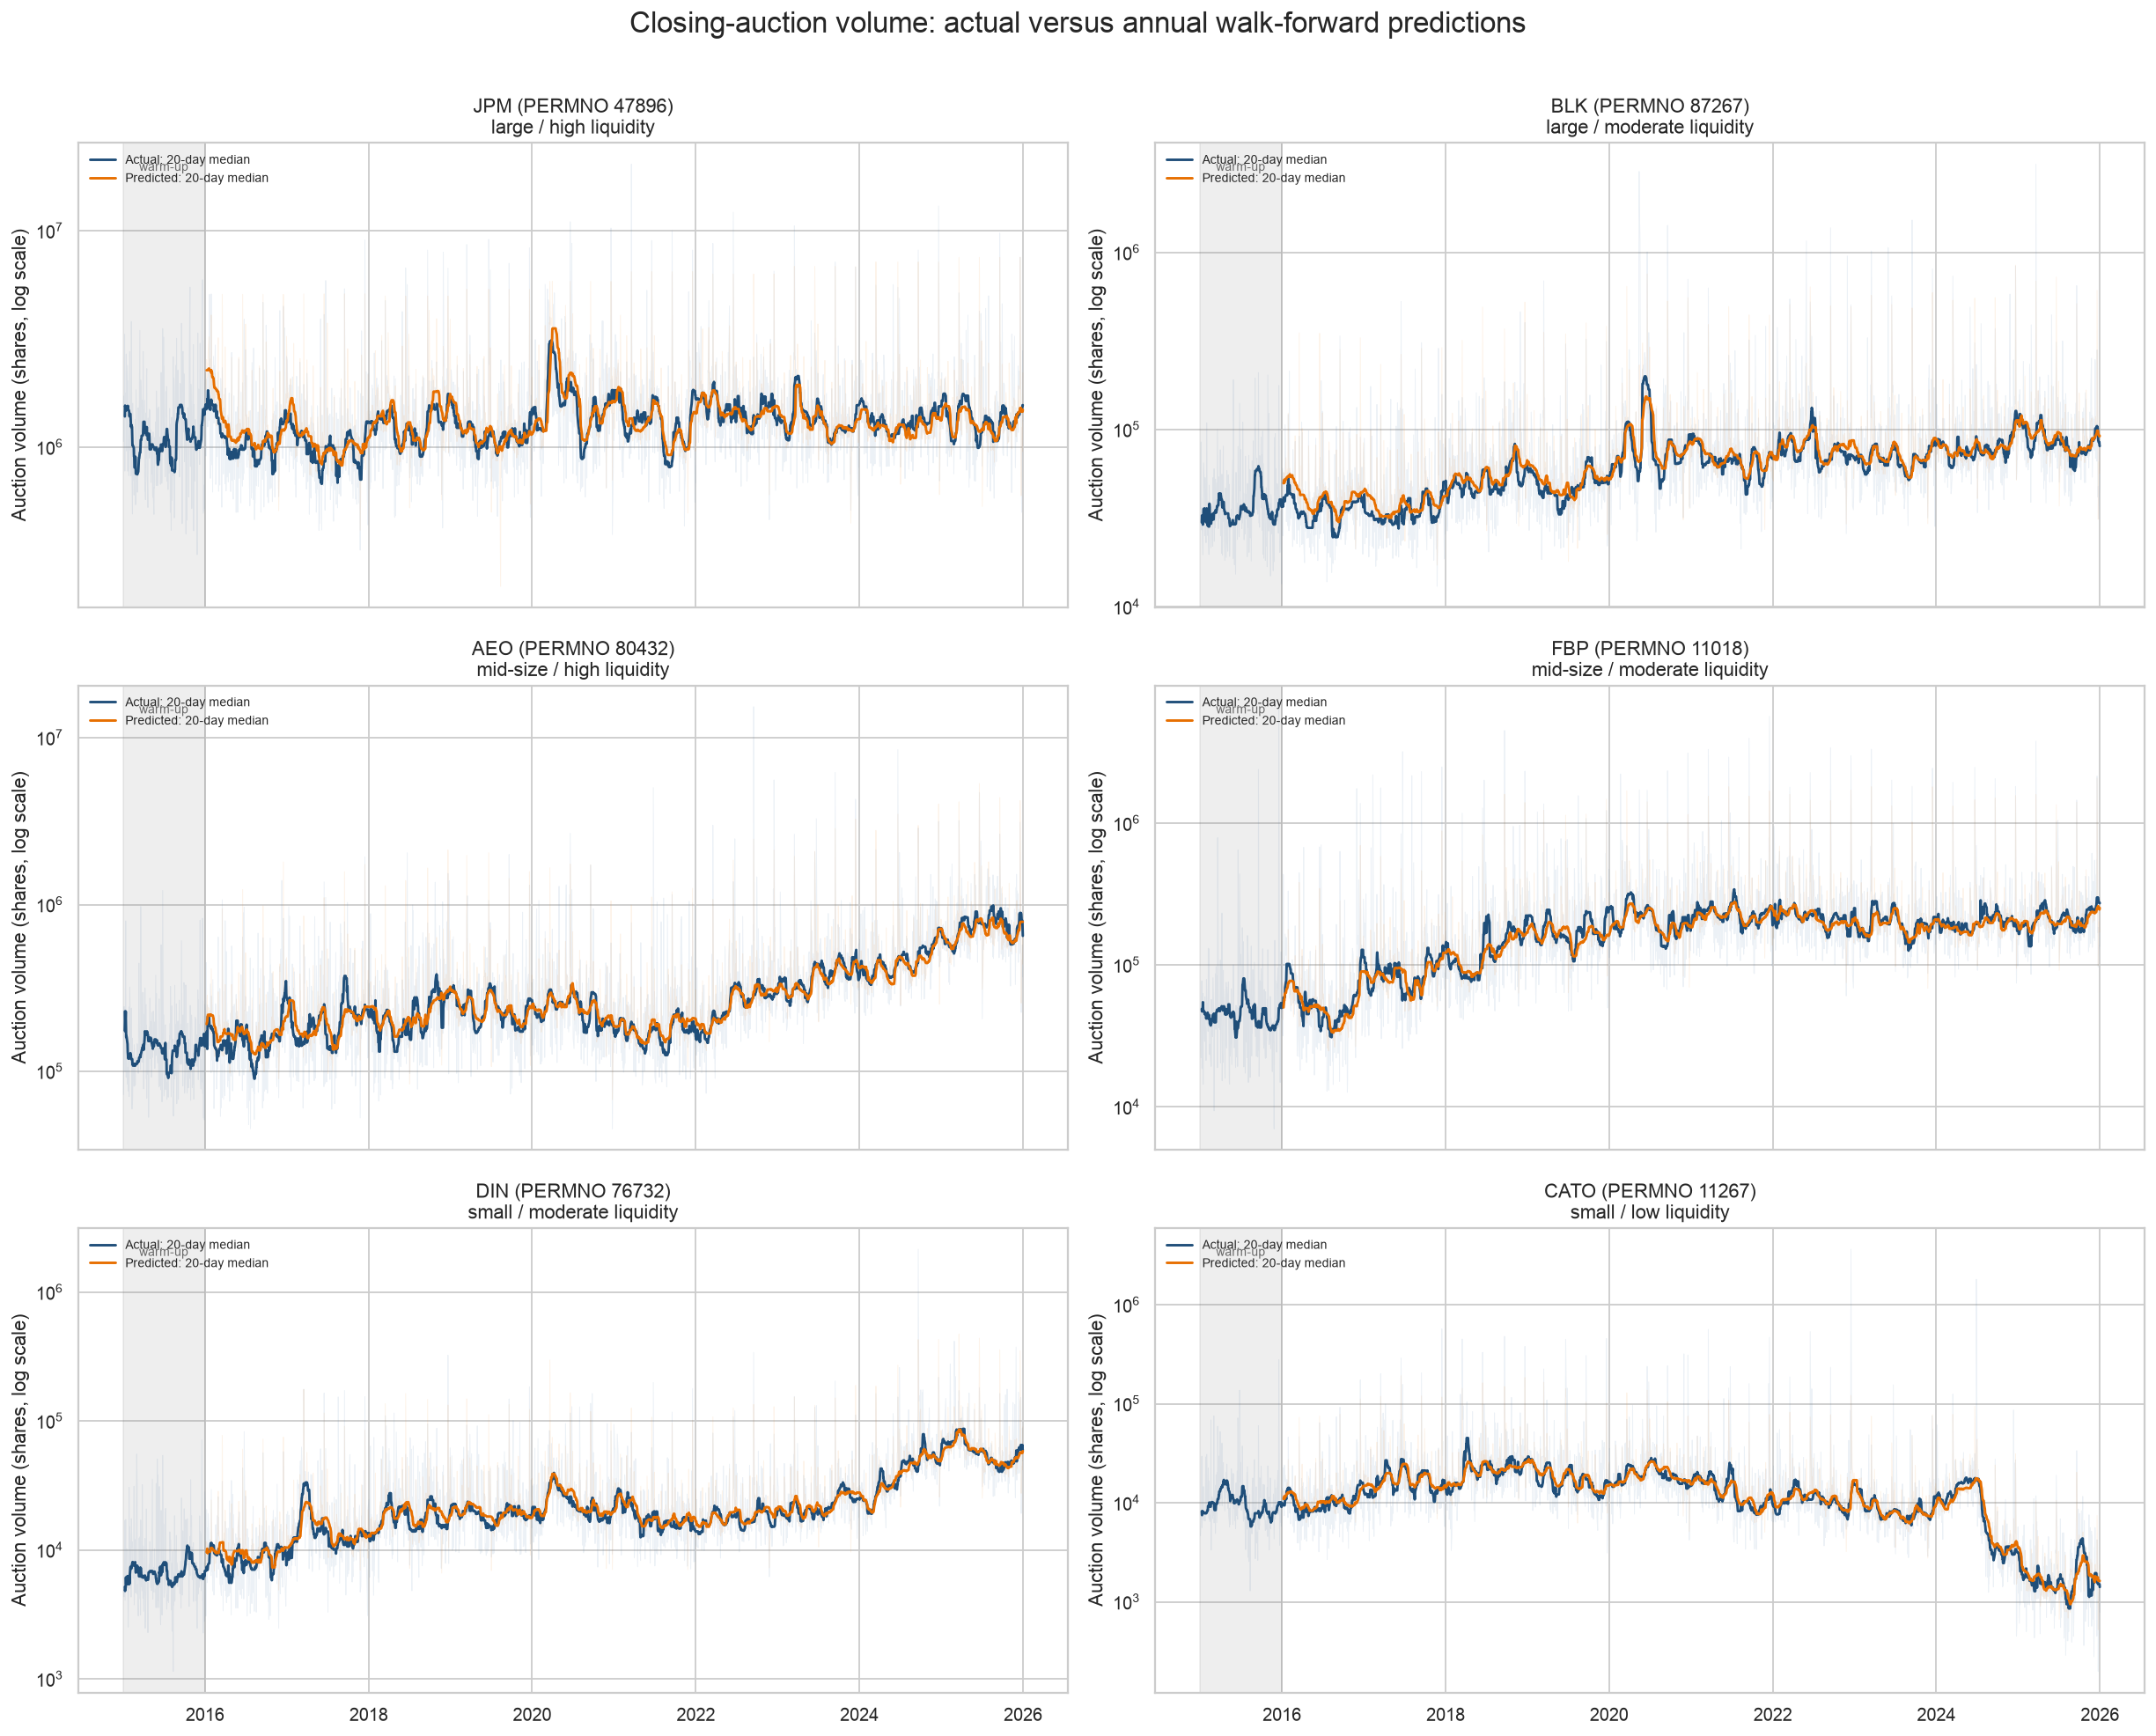

In [5]:
plot_data = predictions.copy()
plot_data["date"] = pd.to_datetime(plot_data["date"])
plot_data["actual_roll20"] = plot_data.groupby("permno")["auction_volume"].transform(
    lambda s: s.rolling(20, min_periods=5).median()
)
plot_data["prediction_roll20"] = plot_data.groupby("permno")["prediction"].transform(
    lambda s: s.rolling(20, min_periods=5).median()
)

fig, axes = plt.subplots(3, 2, figsize=(19, 15), sharex=True)
for ax, permno in zip(axes.flat, PERMNOS):
    frame = plot_data[plot_data["permno"] == permno]
    ticker, profile = SELECTED[permno]["ticker"], SELECTED[permno]["profile"]
    ax.plot(frame["date"], frame["auction_volume"], color="#4C78A8", alpha=0.10, linewidth=0.55)
    ax.plot(frame["date"], frame["prediction"], color="#F28E2B", alpha=0.10, linewidth=0.55)
    ax.plot(frame["date"], frame["actual_roll20"], color="#1F4E79", linewidth=1.6,
            label="Actual: 20-day median")
    ax.plot(frame["date"], frame["prediction_roll20"], color="#E76F00", linewidth=1.6,
            label="Predicted: 20-day median")
    ax.axvspan(pd.Timestamp("2015-01-01"), pd.Timestamp("2016-01-01"), color="gray", alpha=0.13)
    ax.text(pd.Timestamp("2015-07-01"), 0.96, "warm-up", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8, color="dimgray")
    ax.set_yscale("log")
    ax.set_title(f"{ticker} (PERMNO {permno})\n{profile}")
    ax.set_ylabel("Auction volume (shares, log scale)")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend(frameon=False, loc="upper left", fontsize=8)

fig.suptitle("Closing-auction volume: actual versus annual walk-forward predictions", fontsize=18, y=1.01)
fig.tight_layout()
figure_path = OUT / "selected_stock_actual_vs_walk_forward_predictions.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

In [6]:
artifacts = pd.DataFrame({
    "artifact": ["Daily predictions", "Stock profiles", "Stock metrics", "Lambda history", "Prediction figure"],
    "path": [
        prediction_path, OUT / "selected_stock_profiles.csv",
        OUT / "selected_stock_walk_forward_metrics.csv",
        OUT / "walk_forward_lambda_validation.csv", figure_path,
    ],
})
artifacts["path"] = artifacts["path"].astype(str)
artifacts.to_csv(OUT / "artifact_manifest.csv", index=False)
display(artifacts)

,artifact,path
0,Daily predictions,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,Stock profiles,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,Stock metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
3,Lambda history,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
4,Prediction figure,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
